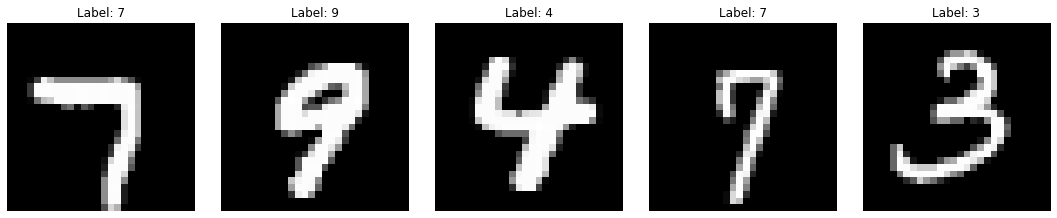

In [51]:
# Code used to import the MNIST dataset. Copied from https://www.geeksforgeeks.org/machine-learning/mnist-dataset/

import torch
import matplotlib.pyplot as plt
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import random

def load_mnist(batch_size=64):
    transform = transforms.ToTensor()
    dataset = datasets.MNIST(
        root="./data",
        train=True,
        download=True,
        transform=transform
    )
    return DataLoader(dataset, batch_size=batch_size, shuffle=True)

def visualize_samples(dataloader, num_samples=5):
    images, labels = next(iter(dataloader))

    plt.figure(figsize=(15, 3))
    for i in range(num_samples):
        plt.subplot(1, num_samples, i + 1)
        plt.imshow(images[i].squeeze(), cmap="gray")
        plt.title(f"Label: {labels[i].item()}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

train_loader = load_mnist(batch_size=64)
visualize_samples(train_loader)

## Model architecture

My plan is to create a model architecture that can adequately encapsulate the problem without being excessively large. Every image in the MNIST data set is a 28x28 pixel greysquare scale. My plan is to assign a numerical value to each picture and use this (28,28) matrice of numbers as the input for the network. My architecture will be as follows:

$$ 784 \rightarrow 128 \rightarrow 64 \rightarrow 10 $$

After testing with 20 neurons and reading online, it seemed more appropriate to have more neurons in the hidden layers. As such we have gone with above to achieve this aim and hope to provide enough depth to be able to effectively model the problem. After the hidden layers, there will be a ReLu function which aims to improve efficiency. NOTE: I have not used this activation functions before, I read up briefly on it and am just trying it out. Each output layer will also be an affine layer. 

Will use CrossEntropyLoss as it is the most appropriate loss for a classification task. Namely, it is used to measure how much a model's predicited probability distribution differs from the true categorical labels. Since we are trying to classify numbers, it helps to achieve this aim. We will use the classic Adam optimiser.

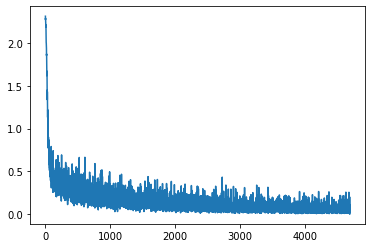

In [38]:
# Number of epochs (runs through the model)
epochs = 5

lossvalues=[]

torch.manual_seed(0)

model = nn.Sequential(
        nn.Flatten(),  # Flattens the inputs so that (batch, 1, 28, 28) -> (batch, 784)
        nn.Linear(784, 128),
        nn.ReLU(),
        nn.Linear(128, 64),
        nn.ReLU(),
        nn.Linear(64, 10),
) 

# Loss and optimiser
loss = nn.CrossEntropyLoss()
optimiser = torch.optim.Adam(model.parameters(), lr=0.001)

# Training loop
for i in range(epochs):
    
    # Setting model to training mode
    model.train() 
    
    # Iterating over the dataset generated by train_loader
    for images, labels in train_loader:
        
        # Clearing gradient values
        optimiser.zero_grad(set_to_none=True)
        
        # Running forward pass and appending loss value to list of loss values
        predictions = model(images).squeeze(1)
        L = loss(predictions, labels)
    
        # Running the backwards pass
        L.backward()
    
        # Updates all paramaters
        optimiser.step()
        lossvalues.append(L.item())
    
plt.plot(lossvalues)

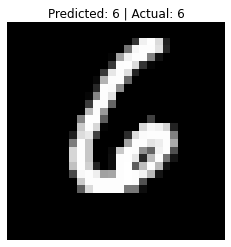

In [80]:
## Code generated from Gen AI to test my model. Seems to work well. 

for i in range(1):

    # 1. Pick a random image and label from your test dataset
    idx = random.randint(0, len(train_loader) - 1)
    image, actual_label = train_loader.dataset[idx]

    # 2. Prepare the image (add batch dimension [1, 1, 28, 28] and move to device)
    input_tensor = image.unsqueeze(0)

    # 3. Run prediction without tracking gradients
    model.eval()
    with torch.no_grad():
        output = model(input_tensor)
        predicted_label = output.argmax(dim=1).item()

    # 4. Display the result
    plt.subplots(1)
    plt.imshow(image.squeeze(), cmap="gray")
    plt.title(f"Predicted: {predicted_label} | Actual: {actual_label}")
    plt.axis("off")
    plt.show()

## Cleaning up the model

Now that we have what appears to be a working model, I am going to try and clean up the overall code, the data cleaning, the overall neural network, the learning curve and the efficacy of the model. Using GenAI I generated a typical piece of code for a MNIST neural network to use as a guide for the clean up. A key difference is that it appears most neural networks maintain a class structure to bundle the model's learnable parameters and forward pass. I will be following this structure. I will maintain the same architecture that I used above, unless otherwise stated, and add lots of comments in the code as a means of explaining what is happening. 

In [79]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

## Step 1: Load data and convert to readable tensors for PyTorch.

# Training data
train_data = datasets.MNIST(
        root='./data',
        train=True,
        download=True,
        transform=transforms.ToTensor()
    )

# Testing data
test_data = datasets.MNIST(
        root='./data',
        train=False,
        download=True,
        transform=transforms.ToTensor()
    )

# Converting the training and testing data into Dataset objects to use in training. batch_size indicates how many
# images to load each batch (i.e. a single batch of data processed in a forward and backwards pass before
# paramater updates). shuffle determines whether to pick new images (True) each time or use the same (False).

train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=1000, shuffle=False)

## Step 2: Defining the neural network using the class structure. NOTE: We call super().__init__() inside __init__() 
# to ensure we use nn.Module's internal paramater and submodule tracking without overuling it in the 
# subclass MNISTNet. This makes sure we can use torch.nn's tools for training and updating paramaters.

class MNISTNet(nn.Module):
    def __init__(self):
        super().__init__()
        # Sets up the neural network layering
        self.network = nn.Sequential(
            nn.Flatten(),  # Flattens the inputs so that (batch, 1, 28, 28) -> (batch, 784)
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10),
        )
    # Calls the forward pass
    def forward(self, x):
        return self.network(x)

# Initialise the model
model = MNISTNet()
# Loss criterion (commonly initialised as criterion) and optimiser
criterion = nn.CrossEntropyLoss()
optimiser = optim.Adam(model.parameters(), lr=1e-3)
    
## Step 3: Training loop

for epoch in range(10):
    # Setting model to training mode
    model.train() 
    # Iterating over the dataset generated by train_loader
    for images, labels in train_loader:
        optimiser.zero_grad()
        predictions = model(images)
        loss = criterion(predictions, labels)
        loss.backward()
        optimiser.step()

## Step 4: Accuracy of the model on test data

total=0
correct=0

# Initialise model to evaluate
model.eval()
# Loop over test data
with torch.no_grad():
    for timages, tlabels in test_loader:
        tpredict = model(timages) # Runs the model on the test images
        predicted = torch.argmax(tpredict, dim=1) # Finds the index of the highest value along dimension 1 
                                                  # to turn the raw model score into a prediction. Since our output
                                                  # is a [1,10] matrix with probability of being each number (0-9)
                                                  # this resultantly selects the value the model predicts.
        total += tlabels.size(0)
        correct += (predicted == tlabels).sum().item()

print(f"Test accuracy: + {correct / total:.4f}")

Test accuracy: + 0.9753


# Results. Moving towards a CNN

Clearly the results are very solid with a test accuracy of around 97.5%. However, there is still room for improvement. 

I believe, the limitation is with this model being a multi-layer perceptron (MLP) as opposed to a convolutional neural network. Unlike an MLP which simply flattens the images and passes them through the layers, a CNN applies one or more convolutions at one or more hidden layers. Roughly speaking, a convolution is a process that uses a filter (called a kernel or convolutional filter) to slide across the input data and information about the data through element-wise multiplication and summation. The output from a kernel filter is known as a feature map. These are often very high dimensional and so CNN's often have a pooling layer too. The pooling layer downsamples feature maps by reducing the spatial dimensions to help lower memory use and prevent overfitting of the model. As such, we are going to try and update the MNIST model above by converting it to a CNN. We will follow the LeNet-5 architecture with the same activation functions and affine layering as above:

<figure style="text-align: center;">
  <img src="https://thumb.wikimedia.org/wikipedia/commons/thumb/3/35/LeNet-5_architecture.svg/960px-LeNet-5_architecture.svg.png?utm_source=en.wikipedia.org&utm_campaign=parser&utm_content=thumbnail" alt="LeNet-5 architecture" width="800">
  <figcaption>Figure 1: LeNet-5 architecture.</figcaption>
</figure>

We will briefly discuss the use of the nn.torch functions nn.Conv2d and nn.MaxPool2d. Both are used in making the CNN. 

The first function nn.Conv2d needs 3 main inputs; in_channels, out_channels and kernel_size, but can take additional inputs like padding. in_channels refers to the number of channels being input which for LeNet-5 is 1 in the first convolution. out_channels is obviously the number of channels after the convolution which is 6 for the first convolution. kernel_size refers to the size of the kernel filter that is applied across the image, namely the size of the grid that is slid across the image pixels. For LeNet-5, the kernel size is 5 so that a $5\times5$ grid is slid across the image. We also add a padding argument of padding=2 which simply adds an additional border of pixels (typically 0) around the incoming $28\times 28$ image. The purpose of this is to increase the size so that it matches the $32\times32$ input for the original LeNet-5 CNN to avoid any dimensionality issues. In the second convolution, we have an input of 6 channels and an output of 16, with the same kernel size and no padding this time since the images are of the appropriate size.

The second function is nn.MaxPool2d which requires an input of kernel_size. kernel_size is the same as above, namely the size of the window that slides across the image. We also input a condition of stride=2 to ensure that after the $2\times2$ window gathers the information, it moves over exactly 2 spaces to start the next. This means that there are no double ups or repeated information. More specifically, the nn.MaxPool2d function is used to reduce the dimension of the feature map. It does this by scanning a kernel filter over an input image and extracting the maximum pixel value, thereby storing this as a new pixel which represents that window. As such for our case, with a kernel size of 2, we are halving the size of the feature map, since it scans a $2\times 2$ window over the inputs and gives us the highest pixel value from those 4 possible values. 

In [4]:
## CNN creation. Code copied from above MLP and updated for CNN.

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

## Step 1: Load data and convert to readable tensors for PyTorch.

train_data = datasets.MNIST(
        root='./data',
        train=True,
        download=True,
        transform=transforms.ToTensor()
    )

test_data = datasets.MNIST(
        root='./data',
        train=False,
        download=True,
        transform=transforms.ToTensor()
    )

train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=1000, shuffle=False)

## Step 2: Defining the neural network using the class structure. 

class CNNNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=6, kernel_size=5, padding=2),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Flatten(),
            nn.Linear(5*5*16, 120),
            nn.ReLU(),
            nn.Linear(120, 84),
            nn.ReLU(),
            nn.Linear(84, 10)
        )
        
    def forward(self, x):
        return self.network(x)

model = CNNNet()
criterion = nn.CrossEntropyLoss()
optimiser = optim.Adam(model.parameters(), lr=1e-3)
    
## Step 3: Training loop

for epoch in range(10):
    model.train()
    for images, labels in train_loader:
        optimiser.zero_grad()
        predictions = model(images)
        loss = criterion(predictions, labels)
        loss.backward()
        optimiser.step()

## Step 4: Accuracy of the model on test data

total=0
correct=0

model.eval()
with torch.no_grad():
    for timages, tlabels in test_loader:
        tpredict = model(timages)
        predicted = torch.argmax(tpredict, dim=1)
        total += tlabels.size(0)
        correct += (predicted == tlabels).sum().item()
        
print(f"Test accuracy: + {correct / total:.4f}")

Test accuracy: + 0.9858


# A working CNN

Well, we have significantly improved our accuracy with the development of the CNN with the model reaching a test accuracy of 98.58%. It is very positive to see and points to the power of a CNN for data detection problems. Moreover, the code below, when placed inside of the final for loop that generates the accuracy of the model, outputs the images of the tests that fail. It was very pleasing to see that the cases that failed where cases where even a human would have struggled with trying to read the writing. Consequently, this indicates that the model is not overfitting the data and accurately solving the problem. 

Future directions may include adjusting the activation functions, training on harder data, improving efficiency and/or memory allocation. But for now, I am very pleased with this.

In [3]:
## Add code inside the above loop over the test data to print out wrong images. They are clearly hard
# to distinguish even by a human. Code below was generated by GenAI.

# # Get a 1D tensor of the indices where predictions were wrong
# wrong_indices = (predicted != tlabels).nonzero(as_tuple=True)[0]
    
# # Check if there is at least 1 wrong prediction using .numel() > 0
# if wrong_indices.numel() > 0:
#     for idx in wrong_indices:
#         # Extract the single image, move to CPU, and remove channel dimension
#         img = timages[idx].cpu().squeeze()
#         plt.figure(figsize=(2, 2))
#         plt.imshow(img, cmap='gray')
#         plt.title(f"Pred: {predicted[idx].item()} | True: {tlabels[idx].item()}")
#         plt.axis('off')
#         plt.show()